In [1]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import elli

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Permittivity changes estimation')
from Permittivity_change_func import *
import Permittivity_change_func
importlib.reload(Permittivity_change_func)
from Permittivity_change_func  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [2]:
Permittivity_change = {}

Energy = np.linspace(1.1, 3.9, 1000)
alpha = 1.42e-5 #in K-1

## Get treated interband contributions

In [3]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Interband sensitivity model\Computed interband changes'
fname = 'Interband contribution - Stoll fit - with Stoll coefficients.csv'

Permittivity_change['ib'] = get_treated_interband_contribution(dir_root, fname)


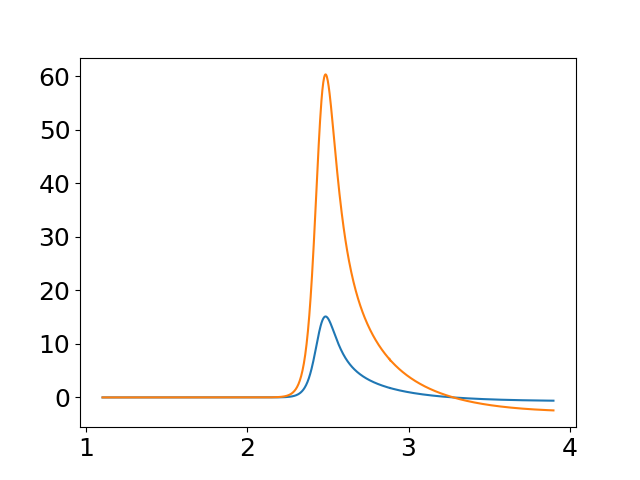

In [4]:
fig, ax = plt.subplots()

ax.plot(Energy, Permittivity_change['ib']['deps2/deV']['Ldp'](Energy))
ax.plot(Energy, Permittivity_change['ib']['delta_eps2']['Ldp'](Energy))

plt.show()

## Get drude contributions

In [5]:
#Gold values from Stoll 2014
w_p = 8.984361811594203 * sc.constants.e / sc.constants.hbar 
gamma_0 = 67*1e-3 * sc.constants.e / sc.constants.hbar

delta_eps1_func, delta_eps2_func = Delta_eps_e_density(w_p = w_p, gamma_0 = gamma_0)
Permittivity_change['Drude'] = {}
Permittivity_change['Drude']['e density'] = {}
Permittivity_change['Drude']['e density']['delta_eps1'] = delta_eps1_func
Permittivity_change['Drude']['e density']['delta_eps2'] = delta_eps2_func

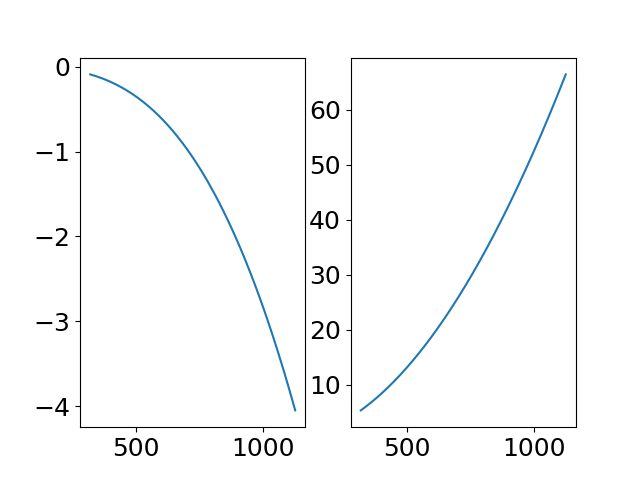

In [6]:
fig, ax = plt.subplots(ncols=2)

ax[0].plot(1240/Energy, Permittivity_change['Drude']['e density']['delta_eps2'](Energy))
ax[1].plot(1240/Energy, Permittivity_change['Drude']['e density']['delta_eps1'](Energy))

plt.show()

## E-ph scattering contribution

In [7]:
dgamma_dT = 0.125e-3 * sc.constants.e / sc.constants.hbar #eV/K


deps1_dT_scattering, deps2_dT_scattering = Delta_eps_e_ph_scattering(w_p, gamma_0, dgamma_dT)

Permittivity_change['Drude']['e-ph scat'] = {}
Permittivity_change['Drude']['e-ph scat']['delta_eps1'] = deps1_dT_scattering
Permittivity_change['Drude']['e-ph scat']['delta_eps2'] = deps2_dT_scattering

### Compare Drude and interband

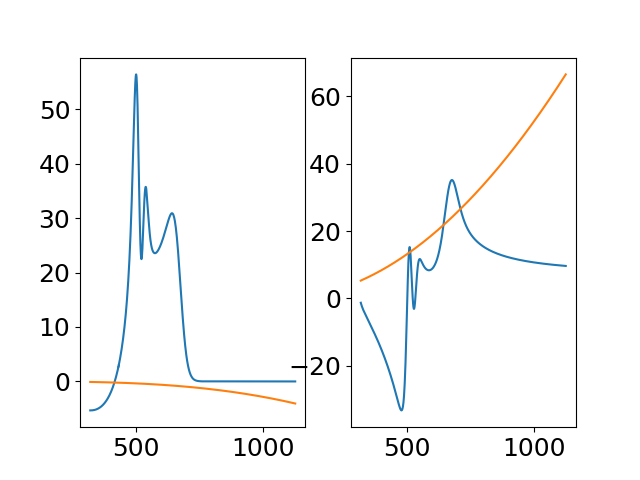

In [8]:
fig, ax = plt.subplots(ncols=2)

ax[0].plot(1240/Energy, Permittivity_change['ib']['delta_eps2']['total'](Energy))
ax[0].plot(1240/Energy, Permittivity_change['Drude']['e density']['delta_eps2'](Energy))


ax[1].plot(1240/Energy, Permittivity_change['ib']['delta_eps1']['total'](Energy))
ax[1].plot(1240/Energy, Permittivity_change['Drude']['e density']['delta_eps1'](Energy))

plt.show()

## Get Cahill data

In [9]:
root_cahill = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Acoustic model - data'
fname_cahill = 'Cahill_eps_variations_dT.csv'


Permittivity_change['Cahill'] = get_Cahill_data(root_cahill, fname_cahill)

## Reproduce thermal variations

In [10]:
deps1_total = Permittivity_change['Drude']['e-ph scat']['delta_eps1'](Energy) + Permittivity_change['Drude']['e density']['delta_eps1'](Energy)*3*alpha + Permittivity_change['ib']['delta_eps1']['total'](Energy)*3*alpha
deps2_total = Permittivity_change['Drude']['e-ph scat']['delta_eps2'](Energy) + Permittivity_change['Drude']['e density']['delta_eps2'](Energy)*3*alpha + Permittivity_change['ib']['delta_eps2']['total'](Energy)*3*alpha

deps1_no_Xband = Permittivity_change['Drude']['e-ph scat']['delta_eps1'](Energy) + Permittivity_change['Drude']['e density']['delta_eps1'](Energy)*3*alpha + (Permittivity_change['ib']['delta_eps1']['total'](Energy) - Permittivity_change['ib']['delta_eps1']['Xdp'](Energy))*3*alpha
deps2_no_Xband = Permittivity_change['Drude']['e-ph scat']['delta_eps2'](Energy) + Permittivity_change['Drude']['e density']['delta_eps2'](Energy)*3*alpha + (Permittivity_change['ib']['delta_eps2']['total'](Energy) - Permittivity_change['ib']['delta_eps2']['Xdp'](Energy))*3*alpha

deps1_Cahill = Permittivity_change['Cahill']['deps1/dT'](Energy)
deps2_Cahill = Permittivity_change['Cahill']['deps2/dT'](Energy)

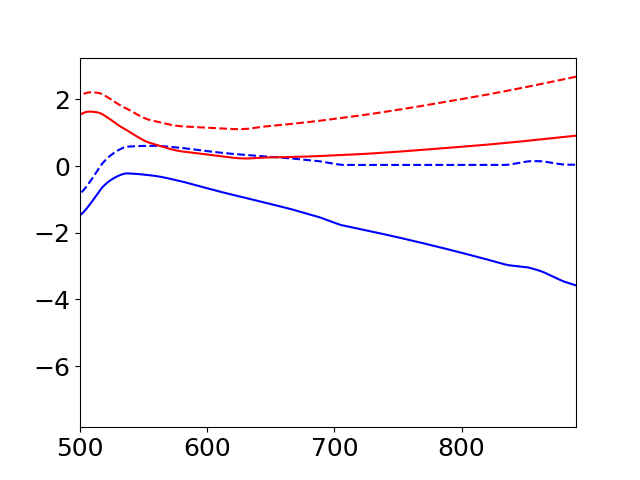

In [11]:
fig, ax = plt.subplots()

ax.plot(1240/Energy, deps2_Cahill*1e3, linestyle='--', color='red')
ax.plot(1240/Energy, deps1_Cahill*1e3, linestyle='--', color='blue')
#ax.plot(1240/Energy, deps2_total*1e3, color='red')
#ax.plot(1240/Energy, deps1_total*1e3, color='blue')

ax.plot(1240/Energy, deps2_Cahill*1e3 - (Permittivity_change['Drude']['e-ph scat']['delta_eps1'](Energy) + Permittivity_change['Drude']['e density']['delta_eps1'](Energy)*3*alpha)*1e3,  color='red')
ax.plot(1240/Energy, deps1_Cahill*1e3 - (Permittivity_change['Drude']['e-ph scat']['delta_eps2'](Energy) + Permittivity_change['Drude']['e density']['delta_eps2'](Energy)*3*alpha)*1e3, color='blue')

#ax.plot(1240/Energy, deps2_no_Xband*1e3, color='purple')
#ax.plot(1240/Energy, deps1_no_Xband*1e3, color='green')
#ax.axhline(0, linestyle='--', color='black')

ax.set_xlim(500, 890)
plt.show()